# 08 · Isle Royale wolves and moose: time-series analysis (Q0–Q5)

**Person 4.** Isle Royale, where hunting, bison and migration are absent. All Q0–Q4 settings come from `scripts/tsa_spec.py`
(written up in `docs/model_settings.md`); Person 1 re-runs Yellowstone with the same module so the two
columns of the comparison table are produced identically.

**Data:** `data/processed/isle_royale_annual.csv` (built by `scripts/build_isle_royale_annual.py`); all paths are relative to the `Person 4` folder.
**Main sample:** 1959–2015 (57 winters; 56 growth rates). 2016–2026 (near-extinction, reintroduction) is treated separately.

**Time alignment:** both systems are counted in winter. Prey growth
y_t = log N_t − log N_(t−1) is the change over the 12 months before count *t*; the wolves present during
those months are the ones counted at *t−1*, so every regressor in row *t* is from year *t−1*.

Sections
0. Describe the series (plots, stationarity, ACF/PACF, ARMA identification)
1. ARIMAX for moose growth (wolves, density, winter) and for wolf growth
2. VAR, Granger causality both ways, impulse responses
3. Cointegration (Engle–Granger, Johansen) and VECM
4. Rolling-origin forecasts 1990–2015
5. Cycle length (periodogram, AR(2), cross-correlation)
6. Isle Royale column of the comparison table

In [1]:
import sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import tsa_spec as spec

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "tables"; TAB.mkdir(parents=True, exist_ok=True)

# One colour per species in every figure (moose = blue, wolves = orange)
C_MOOSE, C_WOLF, C_3, C_4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SHADE = {"parvo_crash": "#d9d6cf", "near_extinction": "#e8e5df", "reintroduction": "#f0efec"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "figure.dpi": 110})

ir = pd.read_csv(ROOT / "data" / "processed" / "isle_royale_annual.csv", index_col="Year")
M_all, W_all = ir["Moose"].astype(float), ir["Wolves"].astype(float)
MAIN = list(range(1959, 2016))                      # main sample (brief): 1959-2015
M, W = M_all.loc[1959:2015], W_all.loc[1959:2015]
print("tsa_spec", spec.SPEC_VERSION, "| main sample", MAIN[0], "-", MAIN[-1], f"({len(MAIN)} years)")

tsa_spec 1.3 (2026-11-18) | main sample 1959 - 2015 (57 years)


## Data notes
- **Moose 1959–2019** are the Wolves and Moose of Isle Royale project series (June 2019 file, via R package `dsem`).
  **2020–2026** come from the NPS table; 2021 and 2025 (no survey) are interpolated and flagged.
- **The two sources disagree on moose before 2003** (median 9 %, up to 50 % around the 1996 crash; wolves agree in 38 of 40 years).
  The project series appears to be the revised, reconstructed series used in the published literature; NPS reports the original
  aerial estimates. The project series is the primary one here; Q1 is re-run on the NPS series as a robustness check.
  Full list: `reports/tables/isle_royale_source_disagreements.csv`.
- **A reconstructed series is smoother than raw counts**, which can make growth rates look less noisy and more autocorrelated
  than a raw survey would. Keep this in mind when comparing volatility with Yellowstone.
- **Climate** (NE Minnesota division, °F and inches) covers 1959–2011 only, so climate models use that shorter window.
- **Kill rates** are not in any reachable table (the annual reports give them only as figures). They are needed only for Q6 step 1.

In [2]:
ir.loc[1959:2026, ["Wolves", "Wolves_source", "Moose", "Moose_source", "Moose_NPS", "Period"]].iloc[::6]

,Wolves,Wolves_source,Moose,Moose_source,Moose_NPS,Period
Year,,,,,,
1959,20,count,538,count,NaN,normal
1965,28,count,634,count,NaN,normal
1971,20,count,1183,count,NaN,normal
1977,34,count,949,count,NaN,normal
1983,23,count,830,count,900.0,normal
1989,12,count,1260,count,1397.0,normal
1995,16,count,2117,count,2400.0,normal
2001,19,count,1120,count,900.0,normal
2007,21,count,385,count,450.0,normal


## 0. Describe the series
### 0.1 Both series, special periods shaded
Two panels on a shared year axis instead of one plot with two y-axes (two scales on one plot invite false visual comparisons).

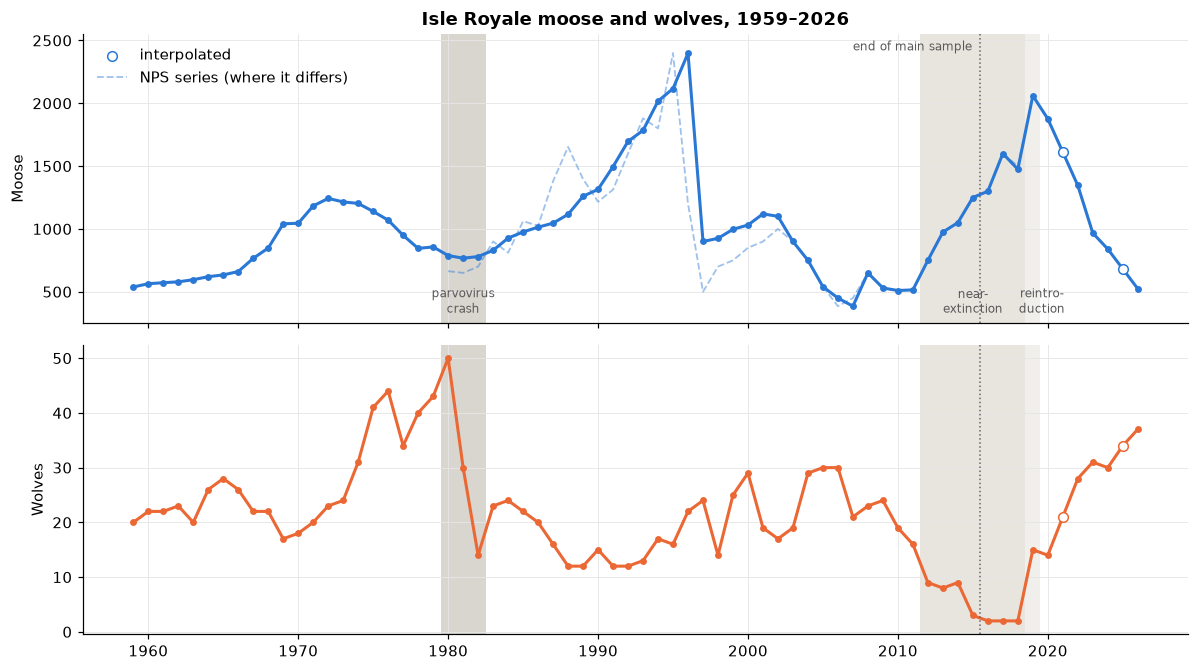

In [3]:
def shade(ax):
    for per, col in SHADE.items():
        yrs = ir.index[ir["Period"] == per]
        if len(yrs):
            ax.axvspan(yrs.min() - 0.5, yrs.max() + 0.5, color=col, lw=0, zorder=0)

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
imp = ir["Moose_imputed"] == 1
for ax, s, col, lab in [(axes[0], M_all, C_MOOSE, "Moose"), (axes[1], W_all, C_WOLF, "Wolves")]:
    shade(ax)
    ax.plot(s.index, s, color=col, marker="o", ms=3.5)
    ax.scatter(s.index[imp], s[imp], s=40, facecolors="white", edgecolors=col, zorder=4, label="interpolated")
    ax.set_ylabel(lab); ax.axvline(2015.5, color="0.4", ls=":", lw=1)
axes[0].plot(ir.index, ir["Moose_NPS"], color=C_MOOSE, alpha=0.45, lw=1.2, ls="--", label="NPS series (where it differs)")
axes[0].legend(loc="upper left", frameon=False)
axes[0].set_title("Isle Royale moose and wolves, 1959–2026")
for per, x in [("parvovirus\ncrash", 1981), ("near-\nextinction", 2015), ("reintro-\nduction", 2019.6)]:
    axes[0].text(x, 300, per, ha="center", va="bottom", fontsize=8, color="0.35")
axes[0].set_ylim(250, 2550)
axes[0].text(2015.2, 2500, "end of main sample ", ha="right", va="top", fontsize=8, color="0.35")
fig.tight_layout(); fig.savefig(FIG / "IR_01_series.png", dpi=200)

### 0.2 Logs and growth rates
r_M,t = log M_t − log M_(t−1), r_W,t likewise.

Largest moose drops: {1997: -0.98, 2005: -0.33, 2009: -0.2}
Largest wolf drops:  {2015: -1.1, 1982: -0.76, 2012: -0.58}


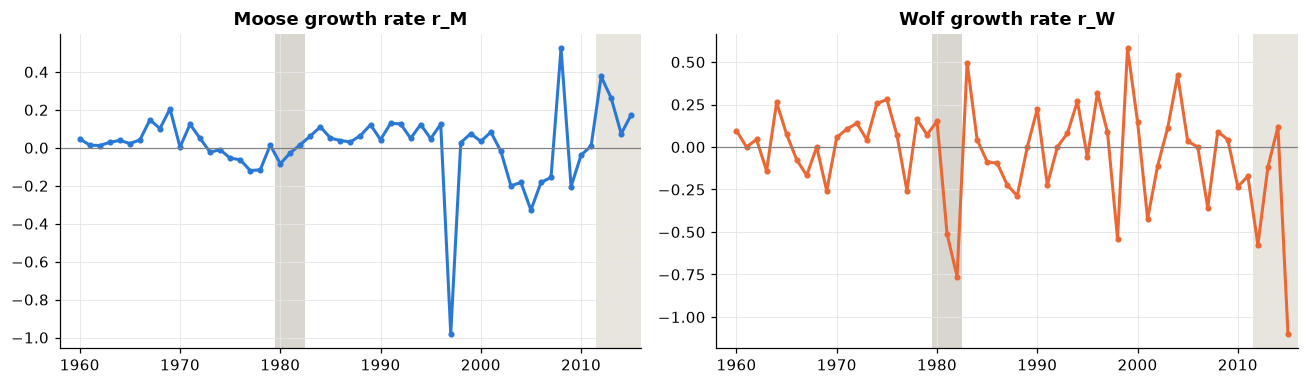

In [4]:
lM, lW = np.log(M), np.log(W)
rM, rW = spec.growth(M), spec.growth(W)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
axes[0].plot(rM.index, rM, color=C_MOOSE, marker="o", ms=3); axes[0].set_title("Moose growth rate r_M")
axes[1].plot(rW.index, rW, color=C_WOLF, marker="o", ms=3); axes[1].set_title("Wolf growth rate r_W")
for ax in axes: ax.axhline(0, color="0.5", lw=0.8); shade(ax); ax.set_xlim(1958, 2016)
fig.tight_layout(); fig.savefig(FIG / "IR_02_growth_rates.png", dpi=200)
print("Largest moose drops:", rM.nsmallest(3).round(2).to_dict())
print("Largest wolf drops: ", rW.nsmallest(3).round(2).to_dict())

### 0.3 Stationarity (ADF at lags 0, 1, 2 + KPSS)
| ADF | KPSS | Conclusion |
|---|---|---|
| rejects (≥ 2 of 3 lags) | does not reject | stationary |
| does not reject | rejects | non-stationary |
| both / neither | | inconclusive |

In [5]:
st = pd.DataFrame([spec.stationarity(lM, "log moose (level)"), spec.stationarity(rM, "moose growth r_M"),
                   spec.stationarity(lW, "log wolves (level)"), spec.stationarity(rW, "wolf growth r_W")]).round(3)
st.to_csv(TAB / "IR_03_stationarity.csv", index=False)
st[["series", "n", "p_lag0", "p_lag1", "p_lag2", "KPSS_p", "ADF says", "KPSS says", "conclusion"]]

,series,n,p_lag0,p_lag1,p_lag2,KPSS_p,ADF says,KPSS says,conclusion
0,log moose (level),57,0.281,0.220,0.144,0.100,unit root,stationary,inconclusive
1,moose growth r_M,56,0.000,0.000,0.002,0.100,stationary,stationary,stationary
2,log wolves (level),57,0.865,0.885,0.969,0.083,unit root,stationary,inconclusive
3,wolf growth r_W,56,0.000,0.000,0.009,0.100,stationary,stationary,stationary


### 0.4 ACF / PACF (bands ±1.96/√n)
An ACF of the log levels that swings from positive to negative is the first hint of a cycle.

ACF of log moose first turns negative at lag 8 | minimum at lag 13 (-0.35)


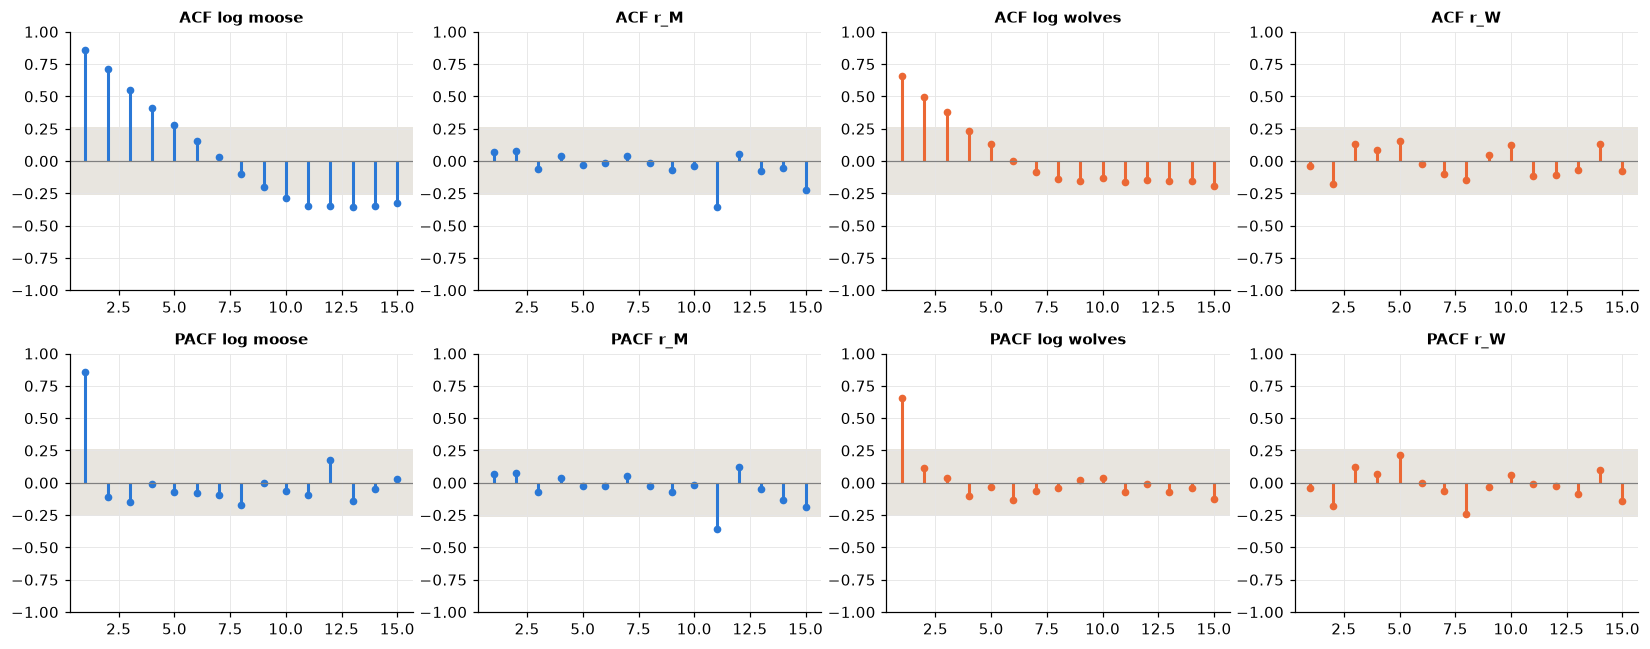

In [6]:
from statsmodels.tsa.stattools import acf, pacf
def acf_panel(ax, x, kind, col, title, lags=15):
    x = x.dropna(); n = len(x)
    v = (acf(x, nlags=lags) if kind == "acf" else pacf(x, nlags=lags, method="ywm"))[1:]
    ax.vlines(range(1, lags + 1), 0, v, color=col, lw=2); ax.plot(range(1, lags + 1), v, "o", color=col, ms=4)
    b = 1.96 / np.sqrt(n); ax.axhspan(-b, b, color="#e8e5df", lw=0); ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(title, fontsize=10); ax.set_ylim(-1, 1)

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for i, (x, col, nm) in enumerate([(lM, C_MOOSE, "log moose"), (rM, C_MOOSE, "r_M"), (lW, C_WOLF, "log wolves"), (rW, C_WOLF, "r_W")]):
    acf_panel(axes[0, i], x, "acf", col, f"ACF {nm}"); acf_panel(axes[1, i], x, "pacf", col, f"PACF {nm}")
fig.tight_layout(); fig.savefig(FIG / "IR_04_acf_pacf.png", dpi=200)
a = acf(lM, nlags=15)
print("ACF of log moose first turns negative at lag", int(np.argmax(a < 0)), "| minimum at lag", int(np.argmin(a)), f"({a.min():.2f})")

### 0.5 ARMA identification on r_M
Candidates from the brief: white noise, AR(1), AR(2), MA(1). Admissible = all AR/MA terms significant and residuals pass Ljung–Box at lag 10; chosen = admissible model with the lowest BIC.

Moose growth has no short-term momentum because yearly change is set mainly by calf survival and the deaths of old moose. Both depend on the current year’s wolves, winter, ticks and food, not on last year’s growth. Those outside drivers are what the ARIMAX and Granger tests pick up.

In [7]:
arma_tab, arma_fits, ORDER = spec.identify_arma(rM.loc[1960:2015])
arma_tab.round(4).to_csv(TAB / "IR_05_arma_identification.csv", index=False)
print("Chosen error model for r_M:", ORDER)
arma_tab.round(3)

Chosen error model for r_M: (0, 0)


,model,coefficients,all terms significant,residual variance,LjungBox_p(lag10),white-noise residuals,AIC,BIC
0,white noise,—,True,0.036,0.999,True,-23.191,-19.140
1,"ARMA(1,0)",ar.L1=0.071 (p=0.67),False,0.036,1.000,True,-21.477,-15.401
2,"ARMA(2,0)","ar.L1=0.066 (p=0.71), ar.L2=0.073 (p=0.73)",False,0.036,1.000,True,-19.779,-11.678
3,"ARMA(0,1)",ma.L1=0.061 (p=0.72),False,0.036,0.999,True,-21.437,-15.361


In [8]:
arma_w, _, ORDER_W = spec.identify_arma(rW.loc[1960:2015])
print("Chosen error model for r_W:", ORDER_W)
arma_w.round(3)[["model", "coefficients", "all terms significant", "LjungBox_p(lag10)", "AIC", "BIC"]]

Chosen error model for r_W: (0, 0)


,model,coefficients,all terms significant,LjungBox_p(lag10),AIC,BIC
0,white noise,—,True,0.576,25.286,29.337
1,"ARMA(1,0)",ar.L1=-0.048 (p=0.73),False,0.582,27.187,33.263
2,"ARMA(2,0)","ar.L1=-0.050 (p=0.73), ar.L2=-0.228 (p=0.27)",False,0.847,26.832,34.933
3,"ARMA(0,1)",ma.L1=-0.081 (p=0.54),False,0.594,27.112,33.188


### 0.6 Do moose and wolves return toward a typical level?

In [9]:
from statsmodels.tsa.arima.model import ARIMA
mr = {}
for s, nm in [(lM, "log moose"), (lW, "log wolves")]:
    ar1 = ARIMA(s, order=(1, 0, 0), trend="c").fit()
    phi, se = ar1.params["ar.L1"], ar1.bse["ar.L1"]
    mr[nm] = {"phi": phi, "95% CI": f"[{phi - 1.96*se:.2f}, {phi + 1.96*se:.2f}]",
              "half-life (yr)": np.log(0.5) / np.log(phi) if 0 < phi < 1 else np.nan}
pd.DataFrame(mr).T

,phi,95% CI,half-life (yr)
log moose,0.883069,"[0.75, 1.01]",5.574072
log wolves,0.889122,"[0.73, 1.05]",5.898076


## 1. ARIMAX for moose growth

r_M,t = μ + β_W·(W_(t−1)/10) + β_D·log M_(t−1) (centred) + β_C·C_(t−1) + ε_t

`tsa_spec.CORE_MODELS` are fitted on the same rows: drift only, wolves alone, density alone, and wolves + density. Error model = the one chosen in 0.5. Expected signs: β_W < 0, β_D < 0.
β × 100 ≈ % change in moose growth per unit (+10 wolves; +1 log-unit of moose, i.e. moose 2.7× higher).

In [10]:
fits, eff, diag = spec.run_core_models(M, W, order=(ORDER[0], 0, ORDER[1]))
eff.round(3).to_csv(TAB / "IR_06_arimax_core.csv", index=False)
print("Error model:", ORDER)
display(eff.round(3)[["model", "term", "pct_per_unit", "pct_CI_low", "pct_CI_high", "p", "n", "AIC", "BIC"]])
print("Diagnostics (Ljung–Box and ARCH p-values; > 0.05 = no problem):")
diag.round(3)

Error model: (0, 0)


,model,term,pct_per_unit,pct_CI_low,pct_CI_high,p,n,AIC,BIC
0,wolves,wolves,-6.407,-16.510,3.695,0.214,56,-26.475,-20.399
1,density,density,-12.852,-25.288,-0.416,0.043,56,-25.239,-19.163
2,wolves + density,wolves,-8.038,-15.964,-0.111,0.047,56,-32.007,-23.906
3,wolves + density,density,-16.885,-30.900,-2.869,0.018,56,-32.007,-23.906


Diagnostics (Ljung–Box and ARCH p-values; > 0.05 = no problem):


,LjungBox_p_lag5,LjungBox_p_lag10,ARCH_p
drift,0.961,0.999,0.943
wolves,0.979,0.987,0.930
density,0.876,0.979,0.950
wolves + density,0.955,0.957,0.962


In [11]:
base = fits["drift"].params["sigma2"]
for k in ["wolves", "density", "wolves + density"]:
    print(f"{k:18s} residual variance {fits[k].params['sigma2']:.4f}  ({100*(1-fits[k].params['sigma2']/base):4.1f}% below drift-only)")

wolves             residual variance 0.0328  ( 9.0% below drift-only)
density            residual variance 0.0335  ( 7.0% below drift-only)
wolves + density   residual variance 0.0287  (20.5% below drift-only)


### 1.1 Adding winter climate (1961–2011, where climate exists)
C = Jan–Feb precipitation (snow) and Jan–Feb temperature from the winter counted at *t−1*, standardised (1 = 1 SD).
Climate variables were fixed in advance (winter only), not searched over, to avoid picking whatever happens to fit.

In [12]:
X = spec.core_regressors(M, W)
z = lambda s: (s - s.mean()) / s.std()
X["snow"] = z(ir["Precip_JanFeb"]).shift(1).reindex(X.index)
X["winter_temp"] = z(ir["Temp_JanFeb"]).shift(1).reindex(X.index)
y = rM.rename("y")
rows = pd.concat([y, X], axis=1).dropna().index
clim_models = {"wolves + density": ["wolves", "density"],
               "wolves + density + winter": ["wolves", "density", "snow", "winter_temp"],
               "winter only": ["snow", "winter_temp"]}
cf = {k: spec.fit_arimax(y.loc[rows], X.loc[rows, v], order=(ORDER[0], 0, ORDER[1]))[0] for k, v in clim_models.items()}
ceff = spec.effect_table(cf); ceff.round(3).to_csv(TAB / "IR_07_arimax_climate.csv", index=False)
print(f"Rows: {rows.min()}–{rows.max()} (n={len(rows)})")
ceff.round(3)[["model", "term", "pct_per_unit", "pct_CI_low", "pct_CI_high", "p", "AIC"]]

Rows: 1960–2012 (n=53)


,model,term,pct_per_unit,pct_CI_low,pct_CI_high,p,AIC
0,wolves + density,wolves,-7.480,-16.608,1.648,0.108,-27.641
1,wolves + density,density,-16.472,-31.514,-1.430,0.032,-27.641
2,wolves + density + winter,wolves,-6.747,-16.058,2.565,0.156,-24.843
3,wolves + density + winter,density,-15.423,-30.517,-0.328,0.045,-24.843
4,wolves + density + winter,snow,-2.571,-8.551,3.410,0.399,-24.843
5,wolves + density + winter,winter_temp,0.722,-6.635,8.078,0.847,-24.843
6,winter only,snow,-4.292,-11.175,2.590,0.222,-20.293
7,winter only,winter_temp,1.091,-7.571,9.754,0.805,-20.293


### 1.2 Robustness of the wolf effect
(a) NPS moose series instead of the project series (1981–2015)  (b) parvovirus crash years removed
(c) up to 2011 (before the near-extinction)  (d) the 1997 moose crash year removed (largest single drop).

In [13]:
Mn = ir["Moose_NPS"].astype(float).loc[1980:2015]
checks = {"main (project series)": (M, W, None),
          "(a) NPS moose series": (Mn, W.loc[1980:2015], None),
          "(b) without 1980–83": (M, W, [t for t in MAIN if t not in range(1980, 1984)]),
          "(c) up to 2011": (M, W, list(range(1959, 2012))),
          "(d) without 1997": (M, W, [t for t in MAIN if t != 1997])}
rob = []
for name, (m_, w_, yrs) in checks.items():
    _, e, _ = spec.run_core_models(m_, w_, years=yrs)
    e = e.set_index(["model", "term"])
    rob.append({"check": name, "n": int(e.loc[("wolves", "wolves"), "n"]),
                "wolves alone: % per +10": e.loc[("wolves", "wolves"), "pct_per_unit"], "p ": e.loc[("wolves", "wolves"), "p"],
                "wolves (with density): %": e.loc[("wolves + density", "wolves"), "pct_per_unit"], "p": e.loc[("wolves + density", "wolves"), "p"],
                "density (with wolves): %": e.loc[("wolves + density", "density"), "pct_per_unit"], "p  ": e.loc[("wolves + density", "density"), "p"]})
rob = pd.DataFrame(rob).set_index("check"); rob.round(3).to_csv(TAB / "IR_08_arimax_robustness.csv")
rob.round(3)

,n,wolves alone: % per +10,p,wolves (with density): %,p,density (with wolves): %,p
check,,,,,,,
main (project series),56,-6.407,0.214,-8.038,0.047,-16.885,0.018
(a) NPS moose series,35,-5.004,0.569,-12.973,0.072,-30.648,0.006
(b) without 1980–83,52,-8.020,0.216,-10.161,0.023,-17.537,0.019
(c) up to 2011,52,-5.020,0.438,-6.801,0.188,-14.526,0.082
(d) without 1997,55,-6.527,0.011,-7.032,0.006,-5.304,0.392


### 1.3 Wolf growth: r_W,t on log M_(t−1) (food supply) and log W_(t−1)

In [14]:
Xw = pd.DataFrame({"log_moose_lag": np.log(M).shift(1) - np.log(M).mean(),
                   "log_wolves_lag": np.log(W).shift(1) - np.log(W).mean(),
                   "moose_per_wolf_lag": np.log(M / W).shift(1) - np.log(M / W).mean()})
yw = rW.rename("rW")
wf = {"food (log M)": spec.fit_arimax(yw, Xw[["log_moose_lag"]])[0],
      "food + own density": spec.fit_arimax(yw, Xw[["log_moose_lag", "log_wolves_lag"]])[0],
      "moose per wolf (ratio)": spec.fit_arimax(yw, Xw[["moose_per_wolf_lag"]])[0]}
weff = spec.effect_table(wf); weff.round(3).to_csv(TAB / "IR_09_wolf_growth.csv", index=False)
display(weff.round(3)[["model", "term", "beta", "pct_CI_low", "pct_CI_high", "p", "AIC"]])
print(pd.DataFrame({k: spec.diagnose(v) for k, v in wf.items()}).T.round(3))

,model,term,beta,pct_CI_low,pct_CI_high,p,AIC
0,food (log M),log_moose_lag,0.147,-13.302,42.627,0.304,25.105
1,food + own density,log_moose_lag,0.140,-15.179,43.089,0.348,27.039
2,food + own density,log_wolves_lag,-0.026,-19.184,13.971,0.758,27.039
3,moose per wolf (ratio),moose_per_wolf_lag,0.082,-4.640,21.116,0.210,25.529


                        LjungBox_p_lag5  LjungBox_p_lag10  ARCH_p
food (log M)                      0.371             0.495   0.334
food + own density                0.424             0.563   0.424
moose per wolf (ratio)            0.512             0.692   0.656


### 1.4 Wolves respond to moose with a delay

In [15]:
import statsmodels.api as sm
Xw3 = pd.concat({f"log_moose_lag{k}": lM.shift(k) for k in (1, 2, 3)} | {"log_wolves_lag1": lW.shift(1)}, axis=1)
dw = pd.concat([lW.diff().rename("rW"), Xw3], axis=1).dropna()
ow = sm.OLS(dw["rW"], sm.add_constant(dw.drop(columns="rW"))).fit()
print(ow.summary().tables[1])
ft = ow.f_test("log_moose_lag1 = 0, log_moose_lag2 = 0, log_moose_lag3 = 0")
print(f"Do moose (lags 1–3) predict wolf growth? F = {float(ft.fvalue):.2f}, p = {float(ft.pvalue):.3f}, R² = {ow.rsquared:.2f}")

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -1.3416      0.854     -1.571      0.123      -3.058       0.374
log_moose_lag1      0.4182      0.230      1.816      0.075      -0.045       0.881
log_moose_lag2     -0.7506      0.297     -2.525      0.015      -1.348      -0.153
log_moose_lag3      0.5346      0.210      2.544      0.014       0.112       0.957
log_wolves_lag1    -0.0236      0.108     -0.219      0.827      -0.240       0.193
Do moose (lags 1–3) predict wolf growth? F = 3.35, p = 0.026, R² = 0.18


## 2. VAR on [r_M, r_W], Granger both ways, impulse responses
Lag chosen by BIC from `select_order(maxlags=3)`; VAR(1) is also fitted because it is the lag used for the
comparison table (Yellowstone's wolf series is only ~30 years long).

In [16]:
V = spec.var_data(M, W)
vo = spec.fit_var(V)
print(vo["order_table"])
print("BIC lag:", vo["selected_lag_bic"], "| AIC lag:", vo["selected_lag_aic"])
gr = pd.DataFrame({"VAR(1) (table)": vo["granger_table"], f"VAR({vo['selected_lag_bic']}) (BIC)": vo["granger_bic"]}).T
gr.to_csv(TAB / "IR_10_granger.csv"); gr

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -5.629     -5.555*    0.003592     -5.600*
1      -5.653      -5.430    0.003508      -5.567
2      -5.655      -5.283    0.003504      -5.512
3     -5.660*      -5.139   0.003495*      -5.459
-------------------------------------------------
BIC lag: 1 | AIC lag: 3


,wolves -> prey p,prey -> wolves p,lag,n
VAR(1) (table),0.011441,0.181905,1.0,55.0
VAR(1) (BIC),0.011441,0.181905,1.0,55.0


In [17]:
# Granger at longer lags: wolves respond to moose with a delay, so lag 1 may be too short to see it
from statsmodels.tsa.api import VAR
rows = []
for p in (1, 2, 3, 4):
    r = VAR(V).fit(p)
    rows.append({"lag": p, "wolves -> moose p": r.test_causality("dlog_prey", ["dlog_wolves"], kind="f").pvalue,
                 "moose -> wolves p": r.test_causality("dlog_wolves", ["dlog_prey"], kind="f").pvalue, "AIC": r.aic, "BIC": r.bic})
lagscan = pd.DataFrame(rows).set_index("lag"); lagscan.round(3).to_csv(TAB / "IR_11_granger_by_lag.csv"); lagscan.round(3)

,wolves -> moose p,moose -> wolves p,AIC,BIC
lag,,,,
1,0.011,0.182,-5.733,-5.514
2,0.021,0.058,-5.695,-5.327
3,0.002,0.195,-5.660,-5.139
4,0.004,0.217,-5.536,-4.860


  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 19, Nov, 2026
Time:                     14:36:14
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   -5.51402
Nobs:                     55.0000    HQIC:                  -5.64832
Log likelihood:           7.57423    FPE:                 0.00323806
AIC:                     -5.73300    Det(Omega_mle):      0.00291175
--------------------------------------------------------------------
Results for equation dlog_prey
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                  0.010452         0.025023            0.418           0.676
L1.dlog_prey           0.030090         0.132095            0.228           0.820
L1.dlog_wolves        -0.251553         0.097704    

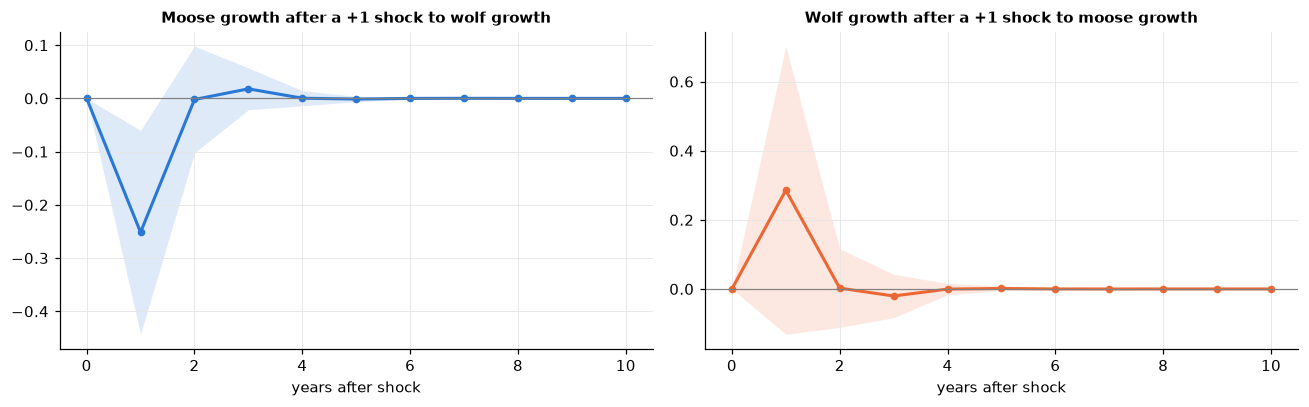

In [18]:
var1 = vo["var_table"]
print(var1.summary())
irf = var1.irf(spec.IRF_HORIZON)
h = np.arange(spec.IRF_HORIZON + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (resp, imp_, col, title) in zip(axes, [(0, 1, C_MOOSE, "Moose growth after a +1 shock to wolf growth"),
                                               (1, 0, C_WOLF, "Wolf growth after a +1 shock to moose growth")]):
    v = irf.irfs[:, resp, imp_]; se = irf.stderr(orth=False)[:, resp, imp_]
    ax.fill_between(h, v - 1.96 * se, v + 1.96 * se, color=col, alpha=0.15, lw=0)
    ax.plot(h, v, color=col, marker="o", ms=4); ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(title, fontsize=10); ax.set_xlabel("years after shock")
fig.tight_layout(); fig.savefig(FIG / "IR_05_var_irf.png", dpi=200)
for nm, (r_, i_) in {"moose to wolf shock": (0, 1), "wolves to moose shock": (1, 0)}.items():
    v = irf.irfs[1:, r_, i_]; k = int(np.argmax(np.abs(v))) + 1
    print(f"{nm}: largest response at year {k} ({v[k-1]:+.3f})")

### 2.1 Granger in levels (Toda–Yamamoto), with and without 1997

In [19]:
def granger_levels(lm, lw, p, drop=()):
    """Regress each log series on p+1 lags of both; test only the first p lags of the other.
    Valid whether or not the log series are stationary."""
    out = {}
    for y, x in [(lm, lw), (lw, lm)]:
        lags = {f"y{k}": y.shift(k) for k in range(1, p + 2)} | {f"x{k}": x.shift(k) for k in range(1, p + 2)}
        d = pd.concat([y.rename("y"), pd.DataFrame(lags)], axis=1).dropna().drop(index=list(drop), errors="ignore")
        o = sm.OLS(d["y"], sm.add_constant(d.drop(columns="y"))).fit()
        out[x.name] = float(o.f_test(", ".join(f"x{k} = 0" for k in range(1, p + 1))).pvalue)
    return out

gl = []
for p in (1, 2, 3, 4):
    for drop, lab in [((), "all years"), ((1997,), "without 1997")]:
        r = granger_levels(lM.rename("moose"), lW.rename("wolves"), p, drop)
        gl.append({"lag p": p, "sample": lab, "wolves → moose p": r["wolves"], "moose → wolves p": r["moose"]})
gl = pd.DataFrame(gl).set_index(["lag p", "sample"])
gl.round(3).to_csv(TAB / "IR_11b_granger_levels.csv"); gl.round(3)

wolves → moose p  moose → wolves p
lag p sample                                          
1     all years                0.006             0.105
      without 1997             0.005             0.111
2     all years                0.017             0.115
      without 1997             0.011             0.113
3     all years                0.006             0.223
      without 1997             0.009             0.219
4     all years                0.017             0.218
      without 1997             0.034             0.221

## 3. Cointegration
Only meaningful if log W and log M are both non-stationary in levels (section 0.3). Engle–Granger (both orderings) and
Johansen (det_order=0, k_ar_diff=1).

In [20]:
co = spec.cointegration(M, W)
co_print = {k: v for k, v in co.items() if k != "data"}
pd.Series(co_print).to_csv(TAB / "IR_12_cointegration.csv"); pd.Series(co_print)

n                                    57
EG wolves~prey p               0.916171
EG prey~wolves p               0.415486
Johansen trace stats      [10.59, 0.79]
trace 5% crit             [15.49, 3.84]
Johansen max-eig stats      [9.8, 0.79]
max-eig 5% crit           [14.26, 3.84]
rank (trace)                          0
rank (max-eig)                        0
dtype: object

In [21]:
from statsmodels.tsa.vector_ar.vecm import VECM
level_verdicts = st.set_index("series")["conclusion"]
print("Levels:", level_verdicts[["log moose (level)", "log wolves (level)"]].to_dict())
rank = co["rank (trace)"]
if rank >= 1:
    vecm = VECM(co["data"], k_ar_diff=spec.JOHANSEN_K_AR_DIFF, coint_rank=1, deterministic="ci").fit()
    print(vecm.summary())
else:
    print("No cointegrating relation at 5 % (rank 0), so a VECM is not supported; it is fitted below only to show the\n"
          "adjustment coefficients, and should not be reported as a result.")
    vecm = VECM(co["data"], k_ar_diff=spec.JOHANSEN_K_AR_DIFF, coint_rank=1, deterministic="ci").fit()
    print("beta (long-run relation, log prey = 1):", vecm.beta.ravel().round(3))
    print("alpha (adjustment):", dict(zip(["log_prey", "log_wolves"], vecm.alpha.ravel().round(3))),
          "| p:", dict(zip(["log_prey", "log_wolves"], vecm.pvalues_alpha.ravel().round(3))))

Levels: {'log moose (level)': 'inconclusive', 'log wolves (level)': 'inconclusive'}
No cointegrating relation at 5 % (rank 0), so a VECM is not supported; it is fitted below only to show the
adjustment coefficients, and should not be reported as a result.
beta (long-run relation, log prey = 1): [1.    0.963]
alpha (adjustment): {'log_prey': np.float64(-0.173), 'log_wolves': np.float64(0.132)} | p: {'log_prey': np.float64(0.001), 'log_wolves': np.float64(0.159)}


## 4. Rolling-origin forecasts, 1990–2015
For each year t: fit on everything up to t−1, forecast the moose count at t. Models: (naive, drift, ARIMAX with wolves, ARIMAX with wolves + density, VAR(1)). MAE in moose, MAPE in %, and the gain over drift.

In [22]:
TEST = list(range(2015 - spec.FORECAST_TEST_YEARS + 1, 2016))
fc = spec.rolling_forecasts(M, W, TEST)
scores = spec.forecast_scores(fc); scores.round(2).to_csv(TAB / "IR_13_forecast_scores.csv")
print(f"Test years {TEST[0]}–{TEST[-1]}"); scores.round(1)

Test years 1990–2015


,years scored,MAE,MAPE %,MAE gain over drift %,MAPE gain over drift %
naive,26.0,182.2,19.8,-7.6,-2.4
drift,26.0,169.3,19.3,0.0,0.0
ARIMAX wolves,26.0,154.4,18.1,8.8,6.2
ARIMAX wolves + density,26.0,161.1,19.7,4.8,-1.8
VAR(1),26.0,175.7,19.7,-3.8,-1.9


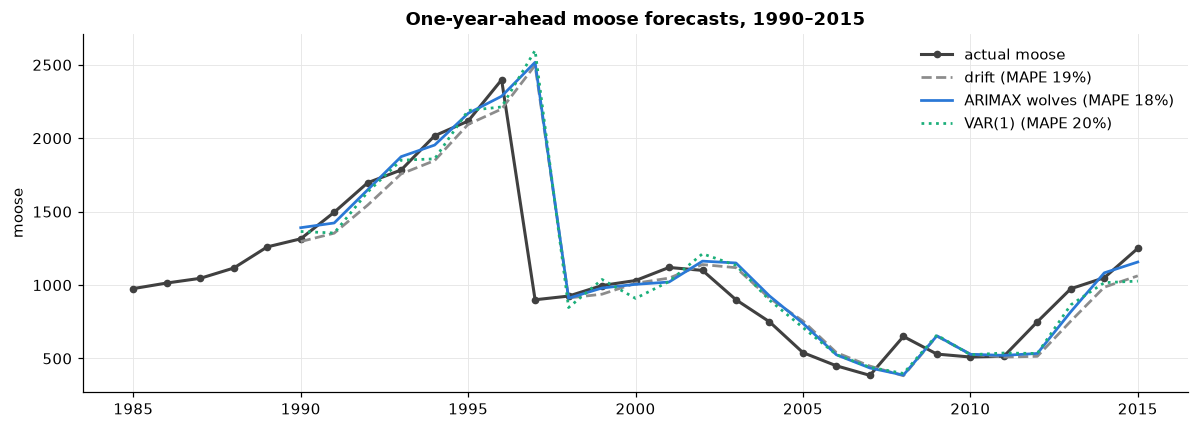

In [23]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(M.loc[1985:].index, M.loc[1985:], color="0.25", marker="o", ms=4, label="actual moose")
for m, col, ls in [("drift", "0.55", "--"), ("ARIMAX wolves", C_MOOSE, "-"), ("VAR(1)", C_3, ":")]:
    ax.plot(fc.index, fc[m], ls, color=col, lw=1.8, label=f"{m} (MAPE {scores.loc[m, 'MAPE %']:.0f}%)")
ax.set_title("One-year-ahead moose forecasts, 1990–2015"); ax.set_ylabel("moose"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "IR_06_rolling_forecasts.png", dpi=200)

## 5. Cycle length
### 5.1 Periodogram of linearly detrended log M and log W (1959–2015)
With 57 years only about two cycles are observed, so the period is approximate. Treat it as consistent with roughly 25–30 years, not a precise estimate.

Dominant period (<= half the sample): {'log moose': np.float64(28.5), 'log wolves': np.float64(28.5)}
Top 3 peaks {period: power}: {'log moose': {28.5: 1.907, 19.0: 1.424, 9.5: 0.387}, 'log wolves': {28.5: 4.86, 14.2: 1.263, 11.4: 0.791}}


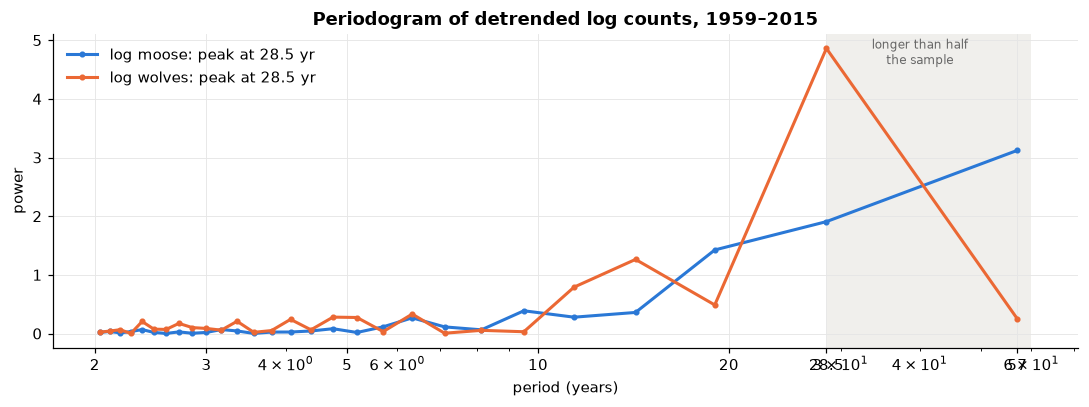

In [24]:
from scipy.signal import periodogram, detrend
fig, ax = plt.subplots(figsize=(10, 3.8)); peaks, top = {}, {}
for s, col, nm in [(lM, C_MOOSE, "log moose"), (lW, C_WOLF, "log wolves")]:
    f, P = periodogram(detrend(s.values), fs=1.0)
    f, P = f[1:], P[1:]
    per = 1 / f
    ok = per <= len(s) / 2
    k = int(np.argmax(np.where(ok, P, -np.inf))); peaks[nm] = per[k]
    top[nm] = pd.Series(P[ok], index=per[ok].round(1)).nlargest(3).round(3).to_dict()
    ax.plot(per, P, color=col, marker="o", ms=3, label=f"{nm}: peak at {per[k]:.1f} yr")
ax.axvspan(len(lM) / 2 + 0.01, 60, color="#f0efec", lw=0)
ax.text(40, ax.get_ylim()[1] * 0.9, "longer than half\nthe sample", ha="center", fontsize=8, color="0.4")
ax.set_xscale("log"); ax.set_xticks([2, 3, 5, 10, 20, 28.5, 57]); ax.set_xticklabels([2, 3, 5, 10, 20, 28.5, 57])
ax.set_xlabel("period (years)"); ax.set_ylabel("power"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Periodogram of detrended log counts, 1959–2015")
fig.tight_layout(); fig.savefig(FIG / "IR_07_periodogram.png", dpi=200)
print("Dominant period (<= half the sample):", {k: round(v, 1) for k, v in peaks.items()})
print("Top 3 peaks {period: power}:", top)

### 5.2 AR(2) on log moose
Complex roots (φ₁² + 4φ₂ < 0) imply a damped cycle with period 2π / arccos(φ₁ / (2√(−φ₂))).

In [25]:
from statsmodels.tsa.arima.model import ARIMA
cyc = {}
for s, nm in [(lM, "log moose"), (lW, "log wolves")]:
    ar2 = ARIMA(s, order=(2, 0, 0), trend="c").fit()
    p1, p2 = ar2.params["ar.L1"], ar2.params["ar.L2"]
    disc = p1**2 + 4 * p2
    period = 2 * np.pi / np.arccos(p1 / (2 * np.sqrt(-p2))) if disc < 0 else np.nan
    cyc[nm] = {"phi1": p1, "phi2": p2, "p(phi2)": ar2.pvalues["ar.L2"], "discriminant": disc,
               "complex roots": disc < 0, "AR(2) period (yr)": period, "damping sqrt(-phi2)": np.sqrt(-p2) if p2 < 0 else np.nan}
cyc = pd.DataFrame(cyc).T; cyc

,phi1,phi2,p(phi2),discriminant,complex roots,AR(2) period (yr),damping sqrt(-phi2)
log moose,1.006458,-0.140078,0.260175,0.452646,False,NaN,0.374269
log wolves,0.899128,-0.011989,0.932943,0.760478,False,NaN,0.109492


### 5.3 Cross-correlation of log M and log W (detrended), lags −10 to +10
Positive lag k = wolves k years **after** moose.

Strongest positive correlation at k = 8 (0.57); among k >= 0: k = 8 (0.57)
Strongest negative correlation at k = -3 (-0.55)
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -1.3416      0.854     -1.571      0.123      -3.058       0.374
log_moose_lag1      0.4182      0.230      1.816      0.075      -0.045       0.881
log_moose_lag2     -0.7506      0.297     -2.525      0.015      -1.348      -0.153
log_moose_lag3      0.5346      0.210      2.544      0.014       0.112       0.957
log_wolves_lag1    -0.0236      0.108     -0.219      0.827      -0.240       0.193


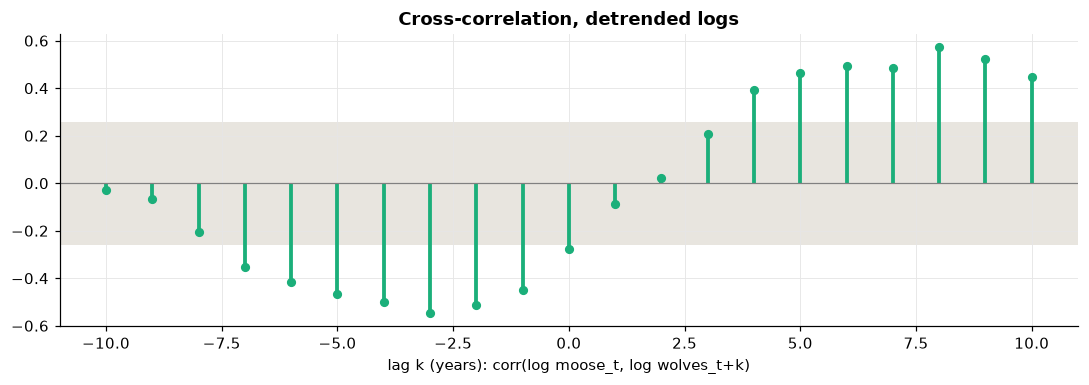

In [27]:
dm, dw = detrend(lM.values), detrend(lW.values)
lags = np.arange(-10, 11)
cc = [np.corrcoef(dm[max(0, -k):len(dm) - max(0, k)], dw[max(0, k):len(dw) - max(0, -k)])[0, 1] for k in lags]
cc = pd.Series(cc, index=lags)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.vlines(lags, 0, cc, color=C_3, lw=2.5); ax.plot(lags, cc, "o", color=C_3, ms=5)
b = 1.96 / np.sqrt(len(dm)); ax.axhspan(-b, b, color="#e8e5df", lw=0); ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("lag k (years): corr(log moose_t, log wolves_t+k)"); ax.set_title("Cross-correlation, detrended logs")
fig.tight_layout(); fig.savefig(FIG / "IR_08_cross_correlation.png", dpi=200)
kpos = cc.loc[0:].idxmax()
print(f"Strongest positive correlation at k = {cc.idxmax()} ({cc.max():.2f}); among k >= 0: k = {kpos} ({cc[kpos]:.2f})")
print(f"Strongest negative correlation at k = {cc.idxmin()} ({cc.min():.2f})")
cyc_tab = pd.DataFrame({"periodogram peak (yr)": pd.Series(peaks), "AR(2) period (yr)": cyc["AR(2) period (yr)"]})
cyc_tab.loc["log moose", "wolves lag moose by (yr)"] = kpos
cyc_tab.round(2).to_csv(TAB / "IR_14_cycle_length.csv"); cyc_tab.round(2)
print(ow.summary().tables[1])

### 5.4 The wolf–moose link before and after the parvovirus crash

In [28]:
rows = {}
for a, b in [(1959, 1980), (1983, 2015)]:
    s = slice(a, b)
    rows[f"{a}–{b}"] = {k: lW.loc[s].corr(lM.shift(k).loc[s]) for k in range(0, 11)}
xc = pd.DataFrame(rows); xc.index.name = "wolves lag moose by k years"
xc.round(2).to_csv(TAB / "IR_14b_crosscorr_by_period.csv"); xc.round(2).T

wolves lag moose by k years,0,1,2,3,4,5,6,7,8,9,10
1959–1980,0.19,0.33,0.48,0.64,0.76,0.81,0.86,0.90,0.88,0.84,0.8
1983–2015,-0.34,-0.12,-0.02,0.19,0.40,0.49,0.53,0.53,0.70,0.71,0.7


## 6. Isle Royale column of the comparison table
Produced by `spec.comparison_row`; Person 1 calls the same function for Yellowstone.

In [29]:
row = spec.comparison_row("Isle Royale", M, W, MAIN, eff, vo, scores)
g_all = gl.xs("all years", level="sample")
row["Granger in levels, wolves → moose, p over lags 1–4"] = f"{g_all['wolves → moose p'].min():.3f}–{g_all['wolves → moose p'].max():.3f}"
row["Granger in levels, moose → wolves, p over lags 1–4"] = f"{g_all['moose → wolves p'].min():.3f}–{g_all['moose → wolves p'].max():.3f}"
row["cointegrated (Johansen rank)"] = co["rank (trace)"]
row["cycle length (periodogram, log moose)"] = f"{peaks['log moose']:.1f} yr"
comp = pd.Series(row, name="Isle Royale"); comp.to_csv(TAB / "IR_comparison_column.csv"); comp.to_frame()

,Isle Royale
system,Isle Royale
years (prey growth),1960–2015 (n=56)
"wolf effect alone, % prey growth per +10 wolves [95% CI]","-6.4 [-16.5, +3.7], p=0.214"
"wolf effect with density, % per +10 wolves [95% CI]","-8.0 [-16.0, -0.1], p=0.047"
"wolf effect with density, % per +1 SD of wolves",-7.4
"Granger p, wolves → prey (VAR(1))",0.011
"Granger p, prey → wolves (VAR(1))",0.182
"forecast MAPE gain over drift, ARIMAX wolves (%)",+6.2
"drift of log prey (mean growth, %/yr)",1.51
"volatility of log prey (SD of growth, %)",19.2


## Summary (plain English)

1. **Wolves hold moose down, and this holds up.** Wolves predict moose in every test: growth-rate VAR (p = 0.011; 0.034 without the 1997 crash) and levels Granger at lags 1–4 (p = 0.005–0.034, with or without 1997). In the ARIMAX, wolf numbers keep a negative sign in all five robustness checks (−5% to −13% moose growth per +10 wolves) and are significant in 3 of 5 (main model with density: −8.0%, 95% CI −16.0 to −0.1, p = 0.047).

2. **Wolves follow moose, with a long delay.** Wolf numbers track moose numbers about 8 years later in both periods (correlation 0.88 in 1959–1980, 0.70 in 1983–2015), and moose 1–3 years back jointly predict wolf growth (p = 0.026). One-year tests miss this (VAR p = 0.18). Likely reason: wolves depend on old, vulnerable moose, which come from calves born about a decade earlier. Caveat: smooth series and about two cycles, so lagged correlati## Summary (plain English)

1. **Wolves hold moose down, and this holds up.** Wolves predict moose in every test: growth-rate VAR (p = 0.011; 0.034 without the 1997 crash) and levels Granger at lags 1–4 (p = 0.005–0.034, with or without 1997). In the ARIMAX, wolf numbers keep a negative sign in all five robustness checks (−5% to −13% moose growth per +10 wolves) and are significant in 3 of 5 (main model with density: −8.0%, 95% CI −16.0 to −0.1, p = 0.047).

2. **Wolves follow moose, with a long delay.** Wolf numbers track moose numbers about 8 years later in both periods (correlation 0.88 in 1959–1980, 0.70 in 1983–2015), and moose 1–3 years back jointly predict wolf growth (p = 0.026). One-year tests miss this (VAR p = 0.18). Likely reason: wolves depend on old, vulnerable moose, which come from calves born about a decade earlier. Caveat: smooth series and about two cycles, so lagged correlations overstate certainty.

3. **The relationship changed after the 1980–82 parvovirus crash.** Before it, wolves and moose rose together; after it, same-year correlation is negative, consistent with wolves suppressing moose.

4. **Density dependence and climate are weak.** The density effect rests on the single 1996–97 crash. Winter snow and temperature add nothing detectable (AIC worse, p = 0.40 and 0.85).

5. **No reliable long-run balance or cycle length.** Both log series pull back toward a typical level with a half-life of about 6 years, but a random walk can't be ruled out (φ ≈ 0.88, CI up to 1.01). No cointegration. The cycle is consistent with roughly 25–30 years but can't be measured precisely from 57 years.

6. **Moose growth has no momentum of its own** (white noise in 0.5): yearly change is set by calf survival and deaths of old moose, which depend on that year's wolves, winter, ticks and food.

7. **Forecasting.** The pre-chosen ARIMAX with wolves beats drift by 6.2% MAPE over 1990–2015. That's modest, because single-winter shocks such as 1996–97 dominate moose growth.ons overstate certainty.

3. **The relationship changed after the 1980–82 parvovirus crash.** Before it, wolves and moose rose together; after it, same-year correlation is negative, consistent with wolves suppressing moose.

4. **Density dependence and climate are weak.** The density effect rests on the single 1996–97 crash. Winter snow and temperature add nothing detectable (AIC worse, p = 0.40 and 0.85).

5. **No reliable long-run balance or cycle length.** Both log series pull back toward a typical level with a half-life of about 6 years, but a random walk can't be ruled out (φ ≈ 0.88, CI up to 1.01). No cointegration. The cycle is consistent with roughly 25–30 years but can't be measured precisely from 57 years.

6. **Moose growth has no momentum of its own** (white noise in 0.5): yearly change is set by calf survival and deaths of old moose, which depend on that year's wolves, winter, ticks and food.

7. **Forecasting.** The pre-chosen ARIMAX with wolves beats drift by 6.2% MAPE over 1990–2015. That's modest, because single-winter shocks such as 1996–97 dominate moose growth.